# Building models

For this prototype, we will be building 2 models and comparing the results between them

One will be a Neural Network model and the other will be a random forest model.



## Neural Network

First we will build the neural network model

In [ ]:
# Importing all the libraries and setting up training and testing dataframes
import os
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from keras import layers, Model
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix


# Ensure TensorFlow backend
os.environ["KERAS_BACKEND"] = "tensorflow"

# Loading dataset
file_url = "alzheimers_disease_data.csv"
dataframe = pd.read_csv(file_url)

# Splitting data into training and testing set
test_dataframe = dataframe.sample(frac=0.2, random_state=1337)
train_dataframe = dataframe.drop(test_dataframe.index)
print(f"Using {len(train_dataframe)} samples for training and {len(test_dataframe)} for validation")


Using 1719 samples for training and 430 for validation


In [25]:
# Convert dataframes to tf.data.Datasets
def dataframe_to_dataset(dataframe, target="Diagnosis"):
    dataframe = dataframe.copy()
    labels = dataframe.pop(target)
    dataframe.pop('PatientID')
    dataframe.pop('DoctorInCharge')
    ds = tf.data.Dataset.from_tensor_slices((dict(dataframe), labels))
    ds = ds.shuffle(buffer_size=len(dataframe)).batch(32)
    return ds

# Creating dataset objects for the dataframes
train_ds = dataframe_to_dataset(train_dataframe)
test_ds = dataframe_to_dataset(test_dataframe)



In [26]:
# Preprocessing layers for numerical and categorical features
def encode_feature(feature, name, dataset, is_string=False):
    lookup_class = layers.StringLookup if is_string else layers.IntegerLookup
    lookup = lookup_class(output_mode="binary")
    feature_ds = dataset.map(lambda x, y: x[name]).map(lambda x: tf.expand_dims(x, -1))
    lookup.adapt(feature_ds)
    return lookup(feature)

def normalize_feature(feature, name, dataset):
    normalizer = layers.Normalization()
    feature_ds = dataset.map(lambda x, y: tf.expand_dims(x[name], -1))
    normalizer.adapt(feature_ds)
    return normalizer(feature)

In [27]:
# Defining and encoding the features
inputs = {
    'Age': layers.Input(name='Age', shape=(1,), dtype='int64'),
    'Gender': layers.Input(name='Gender', shape=(1,), dtype='int64'),
    'Ethnicity': layers.Input(name='Ethnicity', shape=(1,), dtype='int64'),
    'EducationLevel': layers.Input(name='EducationLevel', shape=(1,), dtype='int64'),
    'BMI': layers.Input(name='BMI', shape=(1,), dtype='float32'),
    'Smoking': layers.Input(name='Smoking', shape=(1,), dtype='int64'),
    'AlcoholConsumption': layers.Input(name='AlcoholConsumption', shape=(1,), dtype='float32'),
    'PhysicalActivity': layers.Input(name='PhysicalActivity', shape=(1,), dtype='float32'),
    'DietQuality': layers.Input(name='DietQuality', shape=(1,), dtype='float32'),
    'SleepQuality': layers.Input(name='SleepQuality', shape=(1,), dtype='float32'),
    'FamilyHistoryAlzheimers': layers.Input(name='FamilyHistoryAlzheimers', shape=(1,), dtype='int64'),
    'CardiovascularDisease': layers.Input(name='CardiovascularDisease', shape=(1,), dtype='int64'),
    'Diabetes': layers.Input(name='Diabetes', shape=(1,), dtype='int64'),
    'Depression': layers.Input(name='Depression', shape=(1,), dtype='int64'),
    'HeadInjury': layers.Input(name='HeadInjury', shape=(1,), dtype='int64'),
    'Hypertension': layers.Input(name='Hypertension', shape=(1,), dtype='int64'),
    'SystolicBP': layers.Input(name='SystolicBP', shape=(1,), dtype='int64'),
    'DiastolicBP': layers.Input(name='DiastolicBP', shape=(1,), dtype='int64'),
    'CholesterolTotal': layers.Input(name='CholesterolTotal', shape=(1,), dtype='float32'),
    'CholesterolLDL': layers.Input(name='CholesterolLDL', shape=(1,), dtype='float32'),
    'CholesterolHDL': layers.Input(name='CholesterolHDL', shape=(1,), dtype='float32'),
    'CholesterolTriglycerides': layers.Input(name='CholesterolTriglycerides', shape=(1,), dtype='float32'),
    'MMSE': layers.Input(name='MMSE', shape=(1,), dtype='float32'),
    'FunctionalAssessment': layers.Input(name='FunctionalAssessment', shape=(1,), dtype='float32'),
    'MemoryComplaints': layers.Input(name='MemoryComplaints', shape=(1,), dtype='int64'),
    'BehavioralProblems': layers.Input(name='BehavioralProblems', shape=(1,), dtype='int64'),
    'ADL': layers.Input(name='ADL', shape=(1,), dtype='float32'),
    'Confusion': layers.Input(name='Confusion', shape=(1,), dtype='int64'),
    'Disorientation': layers.Input(name='Disorientation', shape=(1,), dtype='int64'),
    'PersonalityChanges': layers.Input(name='PersonalityChanges', shape=(1,), dtype='int64'),
    'DifficultyCompletingTasks': layers.Input(name='DifficultyCompletingTasks', shape=(1,), dtype='int64'),
    'Forgetfulness': layers.Input(name='Forgetfulness', shape=(1,), dtype='int64'),
    }

encoded_features = [
    encode_feature(inputs['Age'], 'Age', train_ds),
    encode_feature(inputs['Gender'], 'Gender', train_ds),
    encode_feature(inputs['Ethnicity'], 'Ethnicity', train_ds),
    encode_feature(inputs['EducationLevel'], 'EducationLevel', train_ds),
    encode_feature(inputs['Smoking'], 'Smoking', train_ds),
    encode_feature(inputs['FamilyHistoryAlzheimers'], 'FamilyHistoryAlzheimers', train_ds),
    encode_feature(inputs['CardiovascularDisease'], 'CardiovascularDisease', train_ds),
    encode_feature(inputs['Diabetes'], 'Diabetes', train_ds),
    encode_feature(inputs['Depression'], 'Depression', train_ds),
    encode_feature(inputs['HeadInjury'], 'HeadInjury', train_ds),
    encode_feature(inputs['Hypertension'], 'Hypertension', train_ds),
    encode_feature(inputs['SystolicBP'], 'SystolicBP', train_ds),
    encode_feature(inputs['DiastolicBP'], 'DiastolicBP', train_ds),
    encode_feature(inputs['MemoryComplaints'], 'MemoryComplaints', train_ds),
    encode_feature(inputs['BehavioralProblems'], 'BehavioralProblems', train_ds),
    encode_feature(inputs['Confusion'], 'Confusion', train_ds),
    encode_feature(inputs['Disorientation'], 'Disorientation', train_ds),
    encode_feature(inputs['PersonalityChanges'], 'PersonalityChanges', train_ds),
    encode_feature(inputs['DifficultyCompletingTasks'], 'DifficultyCompletingTasks', train_ds),
    encode_feature(inputs['Forgetfulness'], 'Forgetfulness', train_ds),
    normalize_feature(inputs['BMI'], 'BMI', train_ds),
    normalize_feature(inputs['AlcoholConsumption'], 'AlcoholConsumption', train_ds),
    normalize_feature(inputs['PhysicalActivity'], 'PhysicalActivity', train_ds),
    normalize_feature(inputs['DietQuality'], 'DietQuality', train_ds),
    normalize_feature(inputs['SleepQuality'], 'SleepQuality', train_ds),
    normalize_feature(inputs['CholesterolTotal'], 'CholesterolTotal', train_ds),
    normalize_feature(inputs['CholesterolLDL'], 'CholesterolLDL', train_ds),
    normalize_feature(inputs['CholesterolHDL'], 'CholesterolHDL', train_ds),
    normalize_feature(inputs['CholesterolTriglycerides'], 'CholesterolTriglycerides', train_ds),
    normalize_feature(inputs['MMSE'], 'MMSE', train_ds),
    normalize_feature(inputs['FunctionalAssessment'], 'FunctionalAssessment', train_ds),
    normalize_feature(inputs['ADL'], 'ADL', train_ds)
    ]

Train Accuracy: 92.00%
Test Accuracy: 82.69%


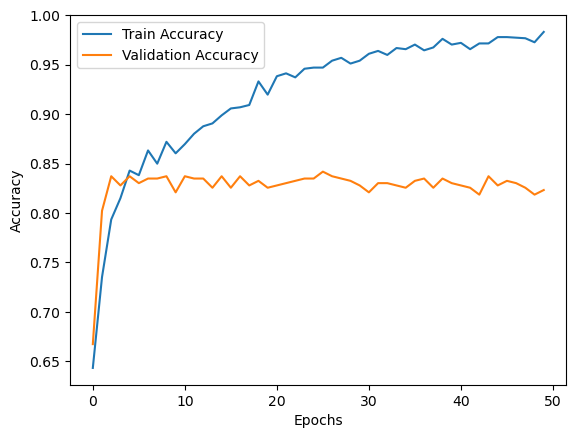

Model accuracy for prediction run after training: 83.72%


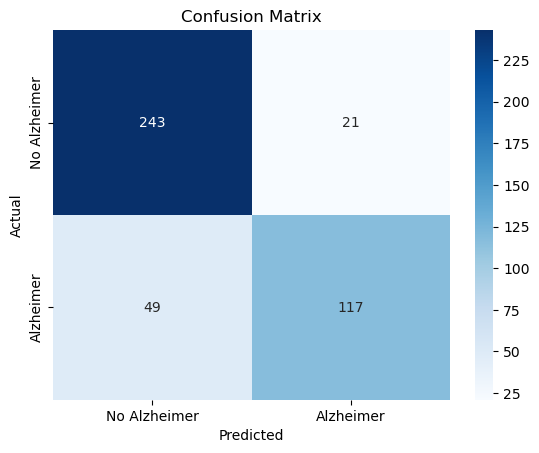

In [47]:
# Building the model
def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(32, activation='relu')(all_features)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='relu')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=50, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=50, validation_data=test_ds, callbacks=early_stopping, verbose=0)

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100:.2f}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100:.2f}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100:.2f}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

## Random Forest

Let's will build the neural network model

In [ ]:
# Importing all the libraries and setting up training and testing dataframes
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

# Loading dataset
file_url = "alzheimers_disease_data.csv"
dataframe = pd.read_csv(file_url)

# Removing sequential and unreadible data
dataframe.pop('PatientID')
dataframe.pop('DoctorInCharge')

# Separating features and target and converting to a numpy object
x = dataframe.iloc[:, :-1].values
y = dataframe.iloc[:, -1].values

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)


In [ ]:
# Preprocessing - Applying StandardScaler() to datasets
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


Accuracy: 92.56%


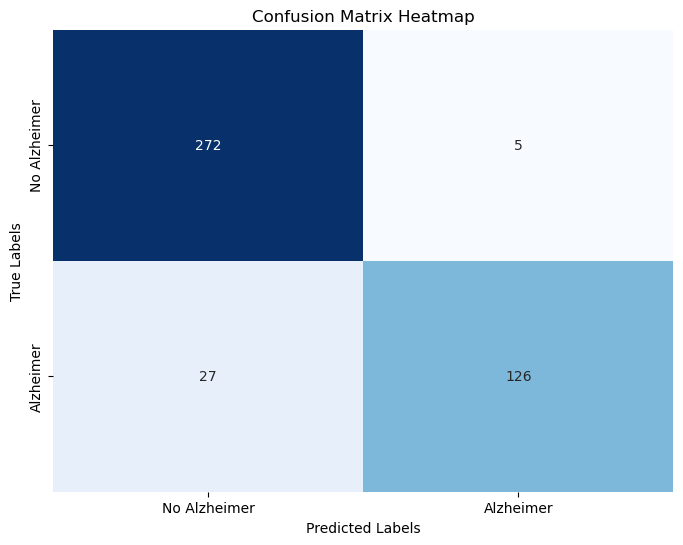

In [ ]:
# Building the model
classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

# Model accuracy for prediction
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

# Plotting confusion matrix to show actual and predicted values for both classes
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False, xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()


